# Visualization of flows

In [224]:
#packages
import os
import pandas as pd 
import numpy as np
import seaborn as sns
from joypy import joyplot
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import ListedColormap

#### Data preparation

In [6]:
years = [1997, 2002, 2007, 2012, 2017, 2022]

In [8]:
#read the data
F0a_1 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F0a_1")
F0b_1 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F0b_1")
#F1_3 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F1_3")
F1_3 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F1_3_Holt")
#F2_1 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F2_1")
F2_1 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F2_1_Holt")
F3_0 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "total_exp") # sheet F3_0 is Holt exports
F3_4 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F3_4")
F4_3 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "reuse_flows") #precalculated data, based on F8_0 and C&D reuse
F4_5 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F4_5")
F4_6 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F4_6")
F4_7 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F4_7")
F4_8 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F4_8")
F5_7 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F5_7")
F5_8 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F5_8")
deltaS7 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "deltaS7")
F8_0 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F8_0")#with m != "green waste","food" and "final products"
#deltaS3 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "deltaS3")
deltaS3 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "deltaS3_Holt")

In [10]:
F0a_1 = F0a_1[F0a_1['Year'].isin(years)]
F0b_1 = F0b_1[F0b_1['Year'].isin(years)]
F1_3 = F1_3[F1_3['Year'].isin(years)]
F2_1 = F2_1[F2_1['Year'].isin(years)]
F3_0 = F3_0[F3_0['Year'].isin(years)]
F3_4 = F3_4[F3_4['Year'].isin(years)]
F4_3 = F4_3[F4_3['Year'].isin(years)]
F4_5 = F4_5[F4_5['Year'].isin(years)]
F4_6 = F4_6[F4_6['Year'].isin(years)]
F4_7 = F4_7[F4_7['Year'].isin(years)]
F4_8 = F4_8[F4_8['Year'].isin(years)]
F5_7 = F5_7[F5_7['Year'].isin(years)]
F5_8 = F5_8[F5_8['Year'].isin(years)]
F8_0 = F8_0[F8_0['Year'].isin(years)]
deltaS3 = deltaS3[deltaS3['Year'].isin(years)]
deltaS3 = deltaS3[deltaS3['Material'] != "sewage sludge (tonnage data being researched)"]
deltaS7 = deltaS7[deltaS7['Year'].isin(years)]
deltaS7 = (deltaS7.groupby(['Material', 'Year'], as_index=False)['kilotons']
           .sum()
          )

In [12]:
F3_4 = F3_4[F3_4['Material'] != "sewage sludge (tonnage data being researched)"]

In [14]:
exclude = ['green waste', 'food', 'final products', 'sewage sludge (tonnage data being researched)']
F8_0 = F8_0[~F8_0["Material"].isin(exclude)]
F8_0 = (F8_0.rename(columns={'Tons':'kilotons'})
       .groupby(['Material', 'Year'], as_index=False)['kilotons']
       .sum())

#### Figures

In [17]:
# Define a custom color palette for products using hex color codes and all categories!
product_colors = {
    "food": "#9ACD32",       
    "construction material and minerals": "#F5DEB3",
    "fossil fuels": "#778899",
    "chemicals": "#D8BFD8",
    "plastic": "#BC8F8F",
    "wood": "#CD853F",
    "paper": "#FAF0E6",
    "final products": "#ADD8E6",
    "metals": "#A9A9A9",
    "electronics": "#D3D3D3",
    "motorized vehicles": "#4682B4",
    "waste": "#DAA520",
    "mixed freight": "#5F9EA0",
    "glass": "#F0FFFF",
    "green waste": "#006400",
    "residual waste and ashes": "#A8968C",
    "sewage sludge": "#6C6C6C"
}

##### DMI - Imports and Domestic Extraction (incl. Packaging materials)
F0a_1, F0b_a, F2_1

In [26]:
display(F0a_1, F0b_1, F2_1)

,Year,Material,Source,Target,kilotons
0,1997,chemicals,Imports,DMI,70.060167
1,1997,construction material and minerals,Imports,DMI,607.350530
2,1997,electronics,Imports,DMI,32.128000
3,1997,final products,Imports,DMI,199.147396
4,1997,food,Imports,DMI,677.318077
...,...,...,...,...,...
73,2022,motorized vehicles,Imports,DMI,103.878164
74,2022,paper,Imports,DMI,75.185845
75,2022,plastic,Imports,DMI,91.008398
76,2022,waste,Imports,DMI,0.006249


,Year,Material,kilotons,Source,Target
0,1997,chemicals,0.000000,Indirect Imports of Packaging,DMI
1,1997,construction material and minerals,0.000000,Indirect Imports of Packaging,DMI
2,1997,electronics,0.000000,Indirect Imports of Packaging,DMI
3,1997,final products,0.000000,Indirect Imports of Packaging,DMI
4,1997,food,0.000000,Indirect Imports of Packaging,DMI
...,...,...,...,...,...
99,2022,paper,50.512040,Indirect Imports of Packaging,DMI
100,2022,plastic,5.652936,Indirect Imports of Packaging,DMI
101,2022,sewage sludge,0.000000,Indirect Imports of Packaging,DMI
102,2022,waste,0.000000,Indirect Imports of Packaging,DMI


,Year,Material,kilotons,Source,Target
0,1997,food,497.433144,DE,DMI
1,2002,food,-20.298023,DE,DMI
2,2007,food,179.514334,DE,DMI
3,2012,food,596.563248,DE,DMI
4,2017,food,607.686571,DE,DMI
5,2022,food,455.802325,DE,DMI
32,1997,construction material and minerals,4443.415673,DE,DMI
37,2002,construction material and minerals,5230.629093,DE,DMI
42,2007,construction material and minerals,7969.413424,DE,DMI
47,2012,construction material and minerals,4322.190792,DE,DMI


In [28]:
pivot = F0b_1.pivot(
    index='Year',
    columns='Material',
    values='kilotons'
).fillna(0)

In [30]:
display(pivot)

Material,chemicals,construction material and minerals,electronics,final products,food,glass,green waste,metals,motorized vehicles,paper,plastic,sewage sludge,waste,wood
Year,,,,,,,,,,,,,,
1997,0.0,0.0,0.0,0.0,0.0,11.068369,0.0,9.738572,0.0,44.346644,2.683674,0.0,0.0,8.789915
2002,0.0,0.0,0.0,0.0,0.0,11.445017,0.0,9.982582,0.0,51.324056,9.131206,0.0,0.0,0.098509
2007,0.0,0.0,0.0,0.0,0.0,20.812653,0.0,13.270354,0.0,62.701248,13.386957,0.0,0.0,0.100498
2012,0.0,0.0,0.0,0.0,0.0,23.063720,0.0,14.207997,0.0,52.001477,7.685841,0.0,0.0,1.417185
2017,0.0,0.0,0.0,0.0,0.0,14.846144,0.0,22.774282,0.0,55.898281,7.679689,0.0,0.0,5.161442
2022,0.0,0.0,0.0,0.0,0.0,9.072162,0.0,13.819333,0.0,50.512040,5.652936,0.0,0.0,5.162153


In [38]:
F0b_1= F0b_1[F0b_1['kilotons'] > 0]

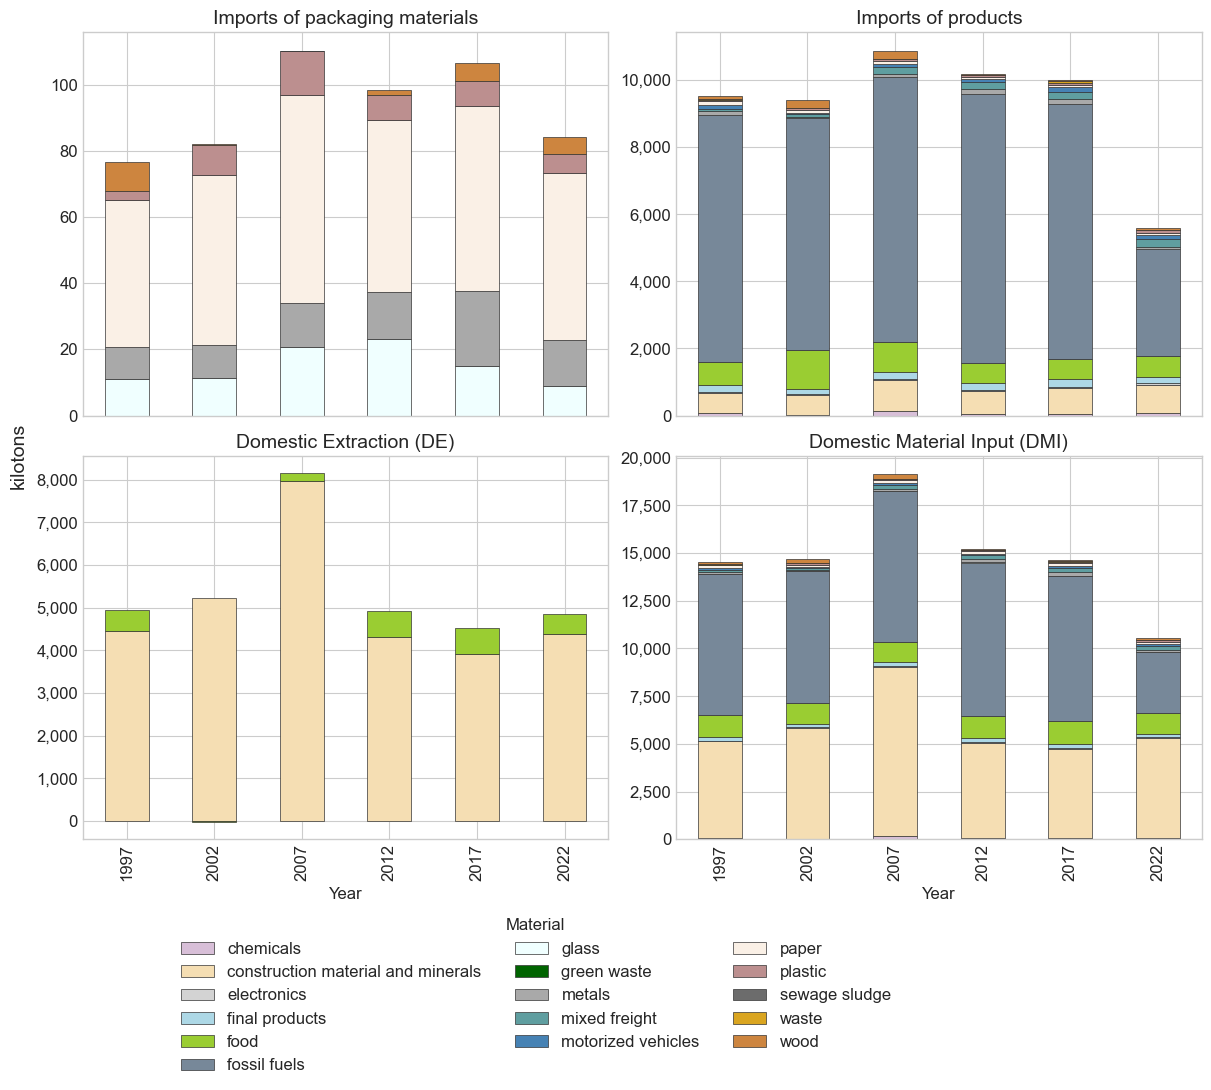

In [48]:
plt.style.use("seaborn-v0_8-whitegrid")
datasets = [F0b_1, F0a_1, F2_1, F1_3]
titles = ["Imports of packaging materials", "Imports of products", "Domestic Extraction (DE)", "Domestic Material Input (DMI)"]

plt.rcParams.update({
    "axes.labelsize": 12,   # Achsenbeschriftung
    "xtick.labelsize": 12,  # x-Ticks
    "ytick.labelsize": 12   # y-Ticks
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 9),
    sharex=True,
    layout="constrained"
)

#axes[1,1].sharey(axes[1,0])
axes[1,1].tick_params(labelleft=True)
axes[1,1].spines["left"].set_visible(True)

for ax, data, title in zip(axes.flat, datasets, titles):

    pivot_df = data.pivot(
        index="Year",
        columns="Material",
        values="kilotons"
    )

    pivot_df.plot.bar(
        stacked=True,
        color=[product_colors[col] for col in pivot_df.columns],
        edgecolor="#333333",
        linewidth=0.5,
        ax=ax,
        legend=False   # wichtig → keine Einzellegenden!
    )

    ax.set_title(title, fontsize = 14) #title, fontsize=14, fontweight="bold", fontfamily="Arial"
    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda x, p: f"{int(x):,}".replace(".", ","))
    )

# 🔹 Gemeinsame Y-Beschriftung
fig.supylabel("kilotons", fontsize=14)

# 🔹 Gemeinsame Legende
handles, labels = axes[1,1].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="center right",
    bbox_to_anchor=(0.75, -0.1),
    ncol = 3,
    frameon=False,
    title="Material",
    fontsize = 12,
    title_fontsize = 12
)
# plt.rcParams.update({
#     "font.family": "Arial",      # oder "Times New Roman"
#     "axes.titlesize": 14,
#     "axes.titleweight": "bold"
# })
fig.savefig('inflows.jpg', dpi = 600,bbox_inches='tight')
plt.show()

In [50]:
# subset withoutout high-volume materials
subset1 = (F0a_1
        .query("Material not in ['food', 'fossil fuels', 'construction material and minerals', 'green waste', 'sewage sludge']"))
# subset with high-volume materials
subset2 = subset = (F0a_1
        .query("Material in ['food', 'fossil fuels', 'construction material and minerals']"))

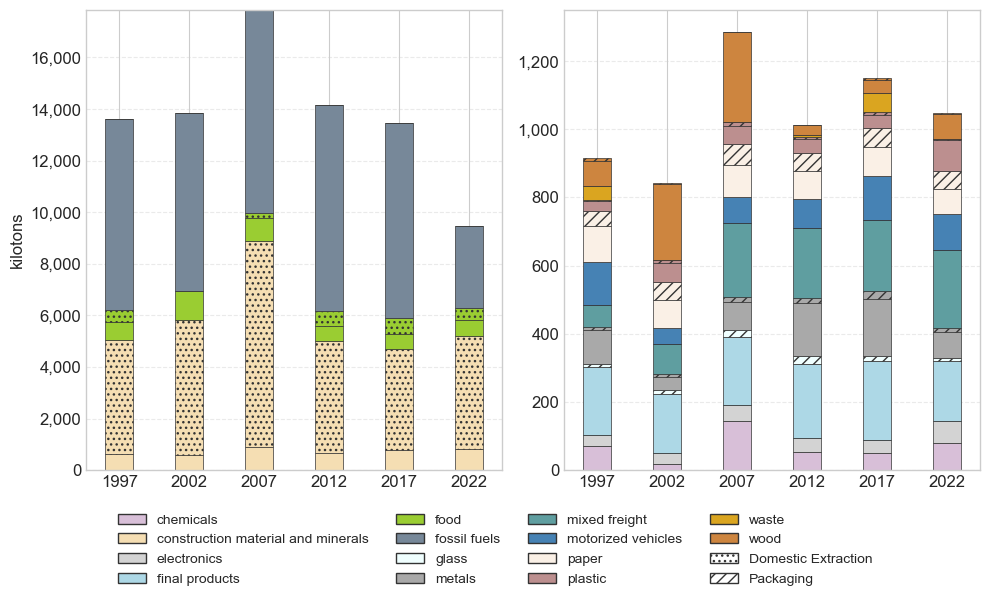

In [56]:
#new version with same legend and different pattern for DE
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 6), sharey=False)

# first plot
pivot_products = subset2.pivot(index="Year", columns="Material", values="kilotons")
pivot_packaging = F2_1.pivot(index="Year", columns="Material", values="kilotons")

materials = sorted(set(pivot_products.columns).union(pivot_packaging.columns))
pivot_products = pivot_products.reindex(columns=materials).fillna(0)
pivot_packaging = pivot_packaging.reindex(columns=materials).fillna(0)

years = pivot_products.index
bottom = np.zeros(len(years))

for mat in materials:
    vals_prod = pivot_products[mat].values
    ax1.bar(years, vals_prod, bottom=bottom,
            color=product_colors.get(mat, "#cccccc"),
            edgecolor="#333333", linewidth=0.5, width = 2)
    bottom += vals_prod

    vals_pack = pivot_packaging[mat].values
    ax1.bar(years, vals_pack, bottom=bottom,
            color=product_colors.get(mat, "#cccccc"),
            edgecolor="#333333", linewidth=0.5, width = 2,
            hatch="...")
    bottom += vals_pack
    ax1.set_xticks(years)
    ax1.set_xticklabels(years)
    ax1.set_ylabel("kilotons")

#ax1.set_title("Imports and Domestic Extraction of high-volume materials", fontsize=12, fontweight="bold")


# second plot
pivot_products = subset1.pivot(index="Year", columns="Material", values="kilotons")
pivot_packaging = F0b_1.pivot(index="Year", columns="Material", values="kilotons")

materials2 = sorted(set(pivot_products.columns).union(pivot_packaging.columns))
pivot_products = pivot_products.reindex(columns=materials2).fillna(0)
pivot_packaging = pivot_packaging.reindex(columns=materials2).fillna(0)

years = pivot_products.index
bottom = np.zeros(len(years))

for mat in materials2:
    vals_prod = pivot_products[mat].values
    ax2.bar(years, vals_prod, bottom=bottom,
            color=product_colors.get(mat, "#cccccc"),
            edgecolor="#333333", linewidth=0.5, width = 2)
    bottom += vals_prod

    vals_pack = pivot_packaging[mat].values
    ax2.bar(years, vals_pack, bottom=bottom,
            color=product_colors.get(mat, "#cccccc"),
            edgecolor="#333333", linewidth=0.5, width = 2,
            hatch="///")
    bottom += vals_pack
    ax2.set_xticks(years)
    ax2.set_xticklabels(years)

#ax2.set_title("Imports of low-volume materials", fontsize=12, fontweight="bold")


# common design
for ax in (ax1, ax2):
    ax.set_facecolor("white")
    ax.grid(True, axis="y", linestyle="--", alpha=0.4)
    ax.set_axisbelow(True)
    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda x, p: f"{int(x):,}".replace(".", ","))
    )


# shared legend
all_materials = sorted(set(materials).union(materials2))

material_handles = [
    Patch(facecolor=product_colors[m], edgecolor="#333333", label=m)
    for m in all_materials
]

hatch_handles = [
    Patch(facecolor="white", edgecolor="#333333", hatch="...", label="Domestic Extraction"),
    Patch(facecolor="white", edgecolor="#333333", hatch="///", label="Packaging")
]

handles = material_handles + hatch_handles
labels = [h.get_label() for h in handles]

fig.legend(handles, labels,
           loc="lower center",
           ncol=4,
           frameon=False)

# Platz für Legende unten schaffen
plt.tight_layout(rect=[0, 0.15, 1, 1])
plt.savefig('input.jpg', dpi = 600,bbox_inches='tight')
plt.show()


##### EoL material shares

In [59]:
comp_reuse = (pd.concat([F4_3, F4_6])
             .groupby(['Material','Year'],as_index=False)['kilotons']
              .sum()
             )

In [61]:
EoL_strat = {
    "Reuse and Composting": comp_reuse,
    "Recycling off island":  F8_0,
    "WtE": F4_5,
    "Landfills": deltaS7
}

In [63]:
dfs = EoL_strat,
colors = product_colors,
value_col="kilotons",
year_col="Year",
material_col="Material",
figsize=(12, 6),
bar_width=0.25,
group_spacing=0.6,
group_order=None

In [65]:
datasets = [comp_reuse,F8_0,F4_5,deltaS7]
titles = ['reuse, recycling and composting', 'exports for recycling', 'WtE', 'landfills']

pivot_tables = [
    df.pivot(index="Year", columns="Material", values="kilotons").fillna(0)
    for df in datasets
]

In [67]:
years = pivot_tables[0].index
n_years = len(years)
n_groups = len(pivot_tables)

x = np.arange(n_years)

bar_width = 0.2
offsets = np.linspace(
    -bar_width*(n_groups-1)/2,
     bar_width*(n_groups-1)/2,
     n_groups
)

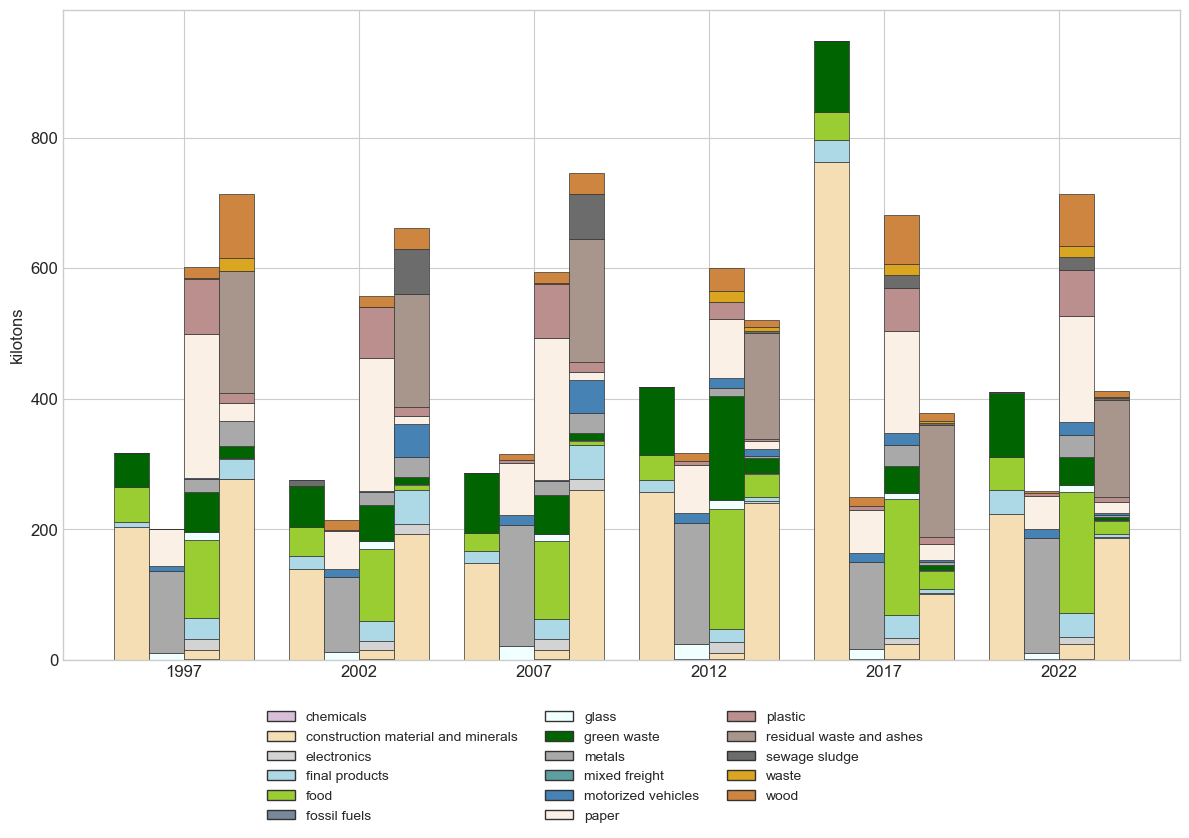

In [69]:
plt.rcParams.update({
    "axes.labelsize": 12,   
    "xtick.labelsize": 12,  
    "ytick.labelsize": 12   
})

fig, ax = plt.subplots(figsize=(12, 7), layout="tight")

for i, (pivot_df, offset, label) in enumerate(zip(pivot_tables, offsets, titles)):

    bottom = np.zeros(n_years)

    for material in pivot_df.columns:

        values = pivot_df[material].values

        ax.bar(
            x + offset,
            values,
            bar_width,
            bottom=bottom,
            color=product_colors.get(material, "#999999"),
            edgecolor="#333333",
            linewidth=0.5,
            label=material if i == 0 else None 
        )

        bottom += values

max_height = 0

for pivot_df in pivot_tables:
    stack_sum = pivot_df.sum(axis=1).max()
    max_height = max(max_height, stack_sum)

ax.set_ylim(0, max_height * 1.05) 

ax.set_xticks(x)
ax.set_xticklabels(years)
ax.yaxis.set_major_formatter(
        FuncFormatter(lambda x, p: f"{int(x):,}".replace(".", ","))
    )

ax.set_ylabel("kilotons")

legend_handles = [
    Patch(facecolor=color, edgecolor="#333333", label=material)
    for material, color in sorted(product_colors.items())
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=3,
    frameon=False#,
    #title="Material"
)

#fig.savefig('EoL.jpg', dpi = 600,bbox_inches='tight')



__Cumulative landfill data__

In [72]:
lf = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "total_waste_DOH_data")

In [74]:
lf.head()

,year,C&D Recycling,C&D Landfill,general recycling (MSW),WtE (MSW),WtE (ash & residue),landfill (MSW),Trash Shipping (MSW),total tonnage,CY WtE (Otsu + C&C Honolulu),WtE (MSW) - WtE (Otsu)
0,1997,175859.290657,214388.0,NaN,NaN,186551.176305,312923.00,NaN,NaN,602357.5,NaN
1,1998,177231.817998,196089.5,NaN,NaN,189174.505041,268925.50,NaN,NaN,610828.0,NaN
2,1999,178604.345338,197717.0,NaN,NaN,186482.732217,270820.25,NaN,NaN,602136.5,NaN
3,2000,179976.872678,187695.0,NaN,NaN,179852.172442,318631.00,NaN,NaN,580727.0,NaN
4,2001,181349.400018,172076.0,NaN,NaN,163857.315482,337449.00,NaN,NaN,529081.0,NaN


In [76]:
lf = lf.drop(columns={'C&D Recycling', 'general recycling (MSW)','CY WtE (Otsu + C&C Honolulu)', 'WtE (MSW)', 'Trash Shipping (MSW)', 'total tonnage', 'WtE (MSW) - WtE (Otsu)'})

In [78]:
lf['C&D Landfill'] = lf['C&D Landfill'].values / 1000
lf['WtE (ash & residue)'] = lf['WtE (ash & residue)'].values / 1000
lf['landfill (MSW)'] = lf['landfill (MSW)'].values / 1000

In [80]:
b1 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name = "factor b1") #2006, landfill
b2 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name = "factor a2") #2017, WtE+landfill
b3 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", sheet_name = "factor b3") #1998, landfill

In [82]:
#b1, b2, b3

In [84]:
factors_b1 = b1.copy().dropna().rename(columns={'mean tons': 'Tons'})
factors_b2 = b2.copy().dropna().rename(columns={'est tons': 'Tons'})
factors_b3 = b3.copy().dropna()
factors_b1["share"] = factors_b1['Tons']/factors_b1['Tons'].sum()
factors_b2["share"] = factors_b2['Tons']/factors_b2['Tons'].sum()
factors_b3["share"] = factors_b3['Tons']/factors_b3['Tons'].sum()

In [86]:
factors_b1 = (
    factors_b1
    .groupby("Material", as_index = False)["share"]
    .sum()
)
factors_b2 = (
    factors_b2
    .groupby("Material", as_index = False)["share"]
    .sum()
)
factors_b3 = (
    factors_b3
    .groupby("Material", as_index = False)["share"]
    .sum()
)
factors_b1['Year'] = 2006
factors_b2['Year'] = 2017
factors_b3['Year'] = 1998

In [88]:
b = pd.concat( 
    [factors_b1, factors_b2, factors_b3],
    ignore_index=True
)
b["Year"] = pd.to_numeric(b["Year"], errors="coerce").astype("Int64")
display(b)

,Material,share,Year
0,chemicals,0.000000,2006
1,construction material and minerals,0.036706,2006
2,electronics,0.050172,2006
3,final products,0.170494,2006
4,food,0.022043,2006
5,glass,0.005167,2006
6,green waste,0.034101,2006
7,metals,0.101454,2006
8,motorized vehicles,0.162178,2006
9,paper,0.042770,2006


In [90]:
wc = b.copy()

In [92]:
def get_wc_for_year(target_year, wc):
    wc = wc.copy()
    wc['dist'] = (wc['Year'] - target_year).abs()
    min_dist = wc['dist'].min()

    closest = wc[wc['dist'] == min_dist]

    # mean, if two years are equally close
    return (
        closest
        .groupby('Material', as_index=False)['share']
        .mean()
        .assign(year=target_year)
    )

In [94]:
rows = []

for _, r in lf.iterrows():
    year = r['year']
    total = r['landfill (MSW)']

    wc_y = get_wc_for_year(year, wc)

    wc_y['kilotons'] = wc_y['share'] * total
    rows.append(wc_y[['year', 'Material', 'kilotons']])

msw_lf_long = pd.concat(rows, ignore_index=True)

In [96]:
msw_lf_long

,year,Material,kilotons
0,1997.0,construction material and minerals,62.721078
1,1997.0,final products,30.105138
2,1997.0,glass,1.567211
3,1997.0,green waste,18.816323
4,1997.0,metals,38.523998
...,...,...,...
348,2023.0,paper,33.978313
349,2023.0,plastic,14.697590
350,2023.0,sewage sludge,4.298733
351,2023.0,waste,3.567042


In [98]:
lf

,year,C&D Landfill,WtE (ash & residue),landfill (MSW)
0,1997,214.38800,186.551176,312.923000
1,1998,196.08950,189.174505,268.925500
2,1999,197.71700,186.482732,270.820250
3,2000,187.69500,179.852172,318.631000
4,2001,172.07600,163.857315,337.449000
5,2002,181.85800,172.812497,307.450750
6,2003,198.26525,187.129544,307.492413
7,2004,233.19200,185.789929,327.878925
8,2005,250.00000,169.011000,391.579000
9,2006,250.00000,191.800000,286.842000


In [100]:
map_simple = {
    'C&D Landfill': 'construction material and minerals',
    'WtE (ash & residue)': 'residual waste and ashes'
}

simple_long = (
    lf
    .melt(
        id_vars='year',
        value_vars=['C&D Landfill', 'WtE (ash & residue)'],
        var_name='Source',
        value_name='kilotons'
    )
    .assign(material=lambda x: x['Source'].map(map_simple))
    #[['year', 'Material', 'kilotons']]
)

In [102]:
simple_long = simple_long.rename(columns={'material': 'Material'})

In [104]:
df_long = pd.concat([simple_long, msw_lf_long], ignore_index=True)

In [106]:
df_long = (
    df_long
    .sort_values(['Material', 'year'])
    .assign(cum_amount=lambda x: x.groupby('Material')['kilotons'].cumsum())
    .drop(columns={'Source'})
)

In [108]:
df_long['year'] = df_long['year'].astype(int)

In [110]:
df_long

,year,kilotons,Material,cum_amount
99,2002,0.000000,chemicals,0.000000
113,2003,0.000000,chemicals,0.000000
127,2004,0.000000,chemicals,0.000000
141,2005,0.000000,chemicals,0.000000
155,2006,0.000000,chemicals,0.000000
...,...,...,...,...
350,2019,5.376530,wood,861.098482
364,2020,6.202175,wood,867.300657
378,2021,11.795892,wood,879.096549
392,2022,8.612351,wood,887.708900


In [112]:
id="prep"

area_df = (
    df_long
    .groupby(['year', 'Material'], as_index=False)['kilotons']
    .sum()
    .pivot(index='year', columns='Material', values='kilotons')
    .fillna(0)
    .sort_index()
)

In [114]:
materials = area_df.columns.tolist()
colors = [product_colors[m] for m in materials]

In [116]:
area_df_cum = area_df.cumsum() #cumulative amount

In [118]:
#area_df_cum.to_excel('cumulative_landfill_1997-2023.xlsx', index = True)

In [122]:
area_df_cum.head()

Material,chemicals,construction material and minerals,electronics,final products,food,glass,green waste,metals,motorized vehicles,paper,plastic,residual waste and ashes,sewage sludge,waste,wood
year,,,,,,,,,,,,,,,
1997,0.0,277.109078,0.0,30.105138,0.0,1.567211,18.816323,38.523998,0.0,27.907778,15.365195,186.551176,0.0,20.070092,97.846188
1998,0.0,527.100967,0.0,55.977443,0.0,2.914069,34.987040,71.631457,0.0,51.891675,28.570017,375.725681,0.0,37.318295,181.935037
1999,0.0,779.100132,0.0,82.032034,0.0,4.270417,51.271690,104.972179,0.0,76.044554,41.867876,562.208414,0.0,54.688023,266.616345
2000,0.0,1030.660300,0.0,112.686317,0.0,5.866215,70.431240,144.198889,0.0,104.461396,57.513346,742.060586,0.0,75.124212,366.247336
2001,0.0,1270.373274,0.0,145.151009,0.0,7.556259,90.722332,185.742287,0.0,134.556504,74.082821,905.917901,0.0,96.767339,471.762425


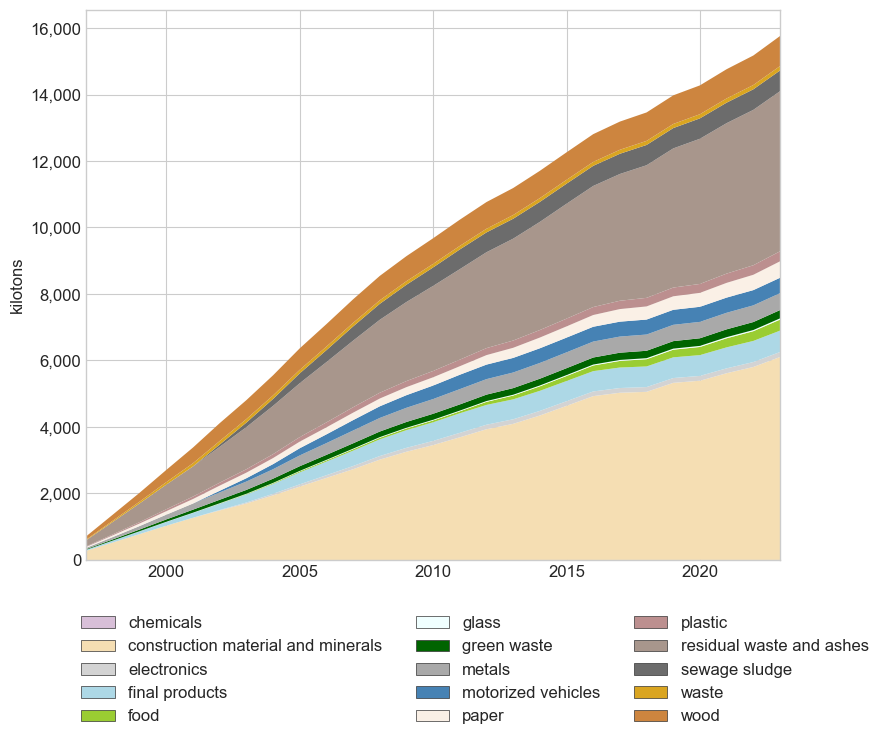

In [124]:
id="plot"

plt.rcParams.update({
    "axes.labelsize": 12,   # Achsenbeschriftung
    "xtick.labelsize": 12,  # x-Ticks
    "ytick.labelsize": 12   # y-Ticks
})


fig, ax = plt.subplots(figsize=(8, 6))

plt.xlim(1997, 2023) 

ax.stackplot(
    area_df_cum.index,
    area_df_cum.T.values,
    labels=materials,
    colors=colors
)

handles = [
    Patch(facecolor=c, edgecolor="#333333", linewidth=0.5, label=m)
    for m, c in zip(materials, colors)
]

fig.legend(
    handles=handles,
    loc="upper center",
    bbox_to_anchor=(0.6, -0.01),
    ncol=3,
    frameon=False,
    #title="Material",
    fontsize=12,
    title_fontsize=12
)

#ax.set_xlabel("Year")
ax.set_ylabel("kilotons")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, p: f"{int(x):,}".replace(".", ",")))
#ax.set_title("Accumulated waste in O'ahu's landfills from 1997 - 2023", fontsize = 14, fontweight="bold")

plt.tight_layout()
#fig.savefig('landfill_accumulation.jpg', dpi = 600,bbox_inches='tight')
plt.show()

__Exports__

In [127]:
F3_0.head()

,Origin,Destination,Material,Source,Target,kilotons,Year
0,Hawaii,Exports to US mainland,food,NAS,Exports,0.000000,1997
1,Hawaii,Exports to US mainland,food,NAS,Exports,0.000000,1997
2,Hawaii,Exports to US mainland,food,NAS,Exports,0.000000,1997
3,Hawaii,Exports to US mainland,food,NAS,Exports,0.000000,1997
4,Hawaii,Exports to US mainland,food,NAS,Exports,0.003576,1997


In [129]:
F3_0 = F3_0[["Material", "Source", "Target", "kilotons", "Year"]]

In [131]:
F3_0 = (
    F3_0
    .groupby(["Year", "Material"], as_index=False)["kilotons"]
    .sum()
)

In [133]:
display(F3_0)

,Year,Material,kilotons
0,1997,chemicals,80.010160
1,1997,construction material and minerals,190.561426
2,1997,electronics,24.087476
3,1997,final products,60.691587
4,1997,food,428.438155
...,...,...,...
73,2022,motorized vehicles,21.879353
74,2022,paper,17.157192
75,2022,plastic,15.218026
76,2022,waste,43.187501


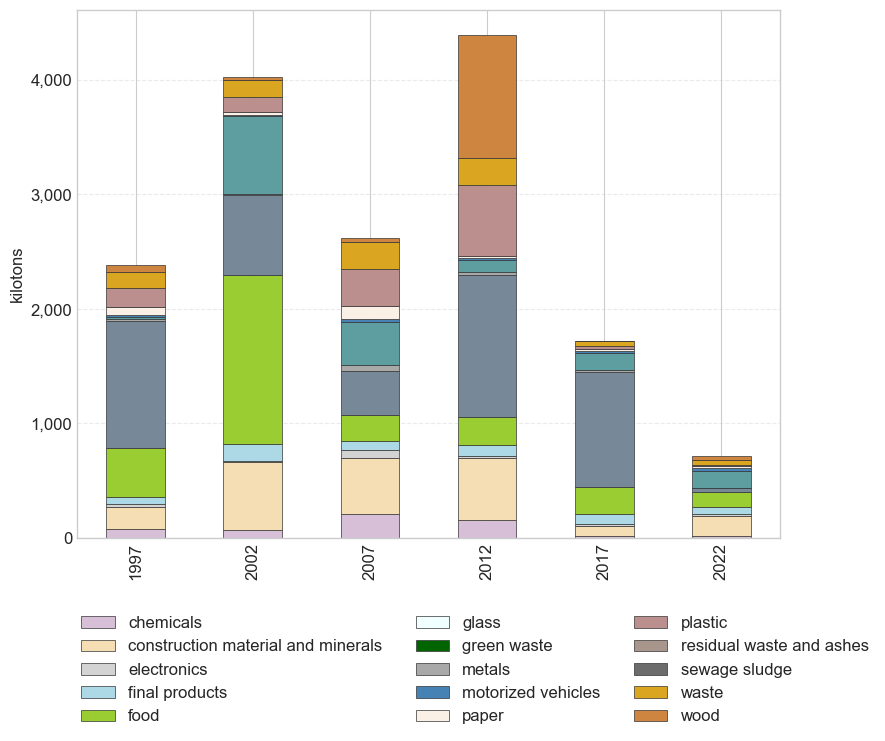

In [135]:
plt.style.use("seaborn-v0_8-whitegrid")

pivot_df = F3_0.pivot(
    index="Year",
    columns="Material",
    values="kilotons"
)

fig, ax = plt.subplots(figsize=(8, 6))

pivot_df.plot.bar(
    stacked=True,
    color=[product_colors[col] for col in pivot_df.columns],
    edgecolor = "#333333",
    linewidth = 0.5,
    ax=ax,
    legend=False
)

# Design
ax.set_facecolor("white")
ax.grid(True, axis="y", linestyle="--", alpha=0.4)
#ax.set_axisbelow(True)

# Titel
#ax.set_title("Exports", fontsize=12, fontweight="bold")

# Tausendertrennzeichen
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, p: f"{int(x):,}".replace(".", ","))
)

fig.legend(
    handles=handles,
    loc="upper center",
    bbox_to_anchor=(0.6, -0.01),
    ncol=3,
    frameon=False,
    #title="Material",
    fontsize=12,
    title_fontsize=12
)

ax.set_ylabel("kilotons")
ax.set_xlabel("")

plt.tight_layout()
fig.savefig('Exports.jpg', dpi = 600,bbox_inches='tight')
plt.show()

## Sankey diagrams

To create sankey diagrams, we need to create one big dataframe, always containing source and target columns, combining in- and outflows of processes.

In [139]:
#read the data
F0a_1 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F0a_1")
F0b_1 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F0b_1")
F1_3 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F1_3")
#F1_3 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F1_3_Holt")
F2_1 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F2_1")
#F2_1 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F2_1_Holt")
F3_0 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "total_exp") # sheet F3_0 is Holt exports
F3_4 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F3_4")
F4_3 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "reuse_flows") #precalculated data, based on F8_0 and C&D reuse
F4_5 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F4_5")
F4_6 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F4_6")
F4_7 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F4_7")
F4_8 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F4_8")
F5_7 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F5_7")
F5_8 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F5_8")
deltaS7 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "deltaS7")
F8_0 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "F8_0") #with m != "green waste","food" and "final products"
deltaS3 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "deltaS3")
#deltaS3 = pd.read_excel("[insert_your_path_here]/SI-B.xlsx", "deltaS3_Holt")

F0a_1 = F0a_1[F0a_1['Year'].isin(years)]
F0b_1 = F0b_1[F0b_1['Year'].isin(years)]
F1_3 = F1_3[F1_3['Year'].isin(years)]
F2_1 = F2_1[F2_1['Year'].isin(years)]
F3_0 = F3_0[F3_0['Year'].isin(years)]
F3_4 = F3_4[F3_4['Year'].isin(years)]
F4_3 = F4_3[F4_3['Year'].isin(years)]
F4_5 = F4_5[F4_5['Year'].isin(years)]
F4_6 = F4_6[F4_6['Year'].isin(years)]
F4_7 = F4_7[F4_7['Year'].isin(years)]
F4_8 = F4_8[F4_8['Year'].isin(years)]
F5_7 = F5_7[F5_7['Year'].isin(years)]
F5_8 = F5_8[F5_8['Year'].isin(years)]
F8_0 = F8_0[F8_0['Year'].isin(years)]

F3_4 = F3_4[F3_4['Material'] != "sewage sludge (tonnage data being researched)"]

exclude = ['green waste', 'food', 'final products', 'sewage sludge (tonnage data being researched)']
F8_0 = F8_0[~F8_0["Material"].isin(exclude)]
F8_0 = (F8_0.rename(columns={'Tons':'kilotons'})
       .groupby(['Material', 'Year'], as_index=False)['kilotons']
       .sum())

In [141]:
df = pd.concat([F0a_1,F0b_1,F1_3,F2_1,F3_0,F3_4,F4_3,F4_5,F4_6,F4_7,F4_8,F5_7,F5_8], ignore_index=True) #F8_0 is excluded

In [143]:
df.head()

,Year,Material,Source,Target,kilotons
0,1997,chemicals,Imports,DMI,70.060167
1,1997,construction material and minerals,Imports,DMI,607.350530
2,1997,electronics,Imports,DMI,32.128000
3,1997,final products,Imports,DMI,199.147396
4,1997,food,Imports,DMI,677.318077


In [145]:
source = set(df['Source'])
target = set(df['Target']) # check if all names match

In [147]:
df = df[df['Material'] != 'sewage sludge (tonnage data being researched)']

In [149]:
df= df.groupby(['Year','Source', 'Target', 'Material']).agg({f'kilotons': 'sum'}).reset_index()
df.head()

,Year,Source,Target,Material,kilotons
0,1997,DE,DMI,construction material and minerals,4443.415673
1,1997,DE,DMI,food,537.577619
2,1997,DMI,NAS,chemicals,70.060167
3,1997,DMI,NAS,construction material and minerals,5050.766203
4,1997,DMI,NAS,electronics,32.128000


In [151]:
#add Reuse and Recycling on island as a dummy flow to show circularity
rr = df[df['Source'] == 'EoL']
rr = rr[rr['Target'] == 'NAS']
rr['Source'] = 'Reuse and Recycling'
rr['Target'] = 'NAS'
mask = (df["Source"] == "EoL") & (df["Target"] == "NAS")
df.loc[mask, "Target"] = "Reuse and Recycling"
df = pd.concat([df, rr], ignore_index = True)

In [153]:
#add Reuse and Recycling on island as a dummy flow to show circularity
rr = df[df['Source'] == 'EoL']
rr = rr[rr['Target'] == 'NAS']
rr['Source'] = 'Reuse and Recycling'
rr['Target'] = 'NAS'

rec = rr.copy()
rec['Source'] = 'EoL'
rec['Target'] = 'Reuse and Recycling'

#remove this from df:
mask = (df["Source"] == "EoL") & (df["Target"] == "NAS")
df = df[~mask]

df = pd.concat([df, rec, rr], ignore_index = True)

In [155]:
# Convert source and target labels to unique numeric indices
nodes = list(set(df['Source']).union(set(df['Target'])))
node_indices = {node: idx for idx, node in enumerate(nodes)}
source_indices = [node_indices[source] for source in df['Source']]
target_indices = [node_indices[target] for target in df['Target']]

In [157]:
nodes

['DE',
 'landfills',
 'EoL',
 'Exports',
 'Reuse and Recycling',
 'NAS',
 'Recycling off island',
 'DMI',
 'Indirect Imports of Packaging',
 'Imports',
 'Composting',
 'WtE']

In [159]:
df.to_excel("sankey_data.xlsx", index = False)

#### 2022 Sankey, for one specific material

In [172]:
node_indices ={
    "DE": 0, 
    "Imports": 1, 
    "Indirect Imports of Packaging": 2, 
    "DMI": 3, 
    "NAS": 4, 
    "Reuse and Recycling": 5, 
    "EoL": 6, 
    "Composting": 7,
    "Exports": 8, 
    "WtE": 9, 
    "Recycling off island": 10, 
    "landfills": 11
}

nodes = [None] * len(node_indices)
for name, idx in node_indices.items():
    nodes[idx] = name
    
source_indices = [node_indices[source] for source in data['Source']]
target_indices = [node_indices[target] for target in data['Target']]
#source_indices, target_indices

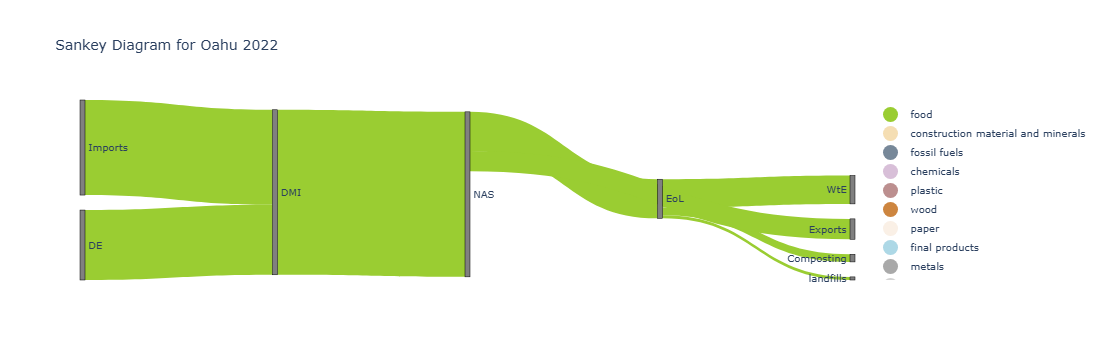

In [174]:
# Create the Sankey diagram for any material and year
year = 2022
material = 'food'

data = df.copy()

data = data[data['Year'] == year]
data = data[data['Material'] == material]

# Convert source and target labels to unique numeric indices
nodes = list(set(data['Source']).union(set(data['Target'])))
node_indices = {node: idx for idx, node in enumerate(nodes)}
source_indices = [node_indices[source] for source in data['Source']]
target_indices = [node_indices[target] for target in data['Target']]

fig = go.Figure(data=[go.Sankey(
    node=dict(
        pad=15,
        thickness=5,
        line=dict(color="black", width=0.5),
        label=nodes,  # Unique labels for nodes
        color="grey"
    ),
    link=dict(
        source=source_indices,  # Source node indices
        target=target_indices,  # Target node indices
        value=data['kilotons'],     # Flow values
        color=[product_colors[product] for product in data['Material']]  # Link colors based on product
    )
)])
    
# Customize layout
fig.update_layout(
    title_text=f"Sankey Diagram for Oahu {year}", font_size=10,
    xaxis_title=None,  # Entfernt die Beschriftung der x-Achse
    yaxis_title=None,  # Entfernt die Beschriftung der y-Achse)
    xaxis=dict(showticklabels=False),  # Entfernt die Tick-Labels der x-Achse
    yaxis=dict(showticklabels=False),   # Entfernt die Tick-Labels der y-Achse
    plot_bgcolor="rgba(0,0,0,0)",  # Entfernt den Plot-Hintergrund (transparent)
    paper_bgcolor="rgba(0,0,0,0)")  # Entfernt den gesamten Figurenhintergrund (transparent)
    
# Add custom legend as scatter traces
for sctg2, color in product_colors.items():
    fig.add_trace(go.Scatter(
        x=[None],  # Dummy x value
        y=[None],  # Dummy y value
        mode='markers',
        marker=dict(size=15, color=color),
        name=sctg2,  # Legend entry
        hoverinfo='none'  # Hide hover text for dummy points
    ))
    
# Show the Sankey diagram
fig.show()

### 2022 Sankey, all materials except: fossil fuels, food, construction material and minerals, sewage sludge, chemicals, green waste

     Year Source Target                            Material     kilotons
568  2022     DE    DMI  construction material and minerals  4387.293043
569  2022     DE    DMI                                food   455.802325


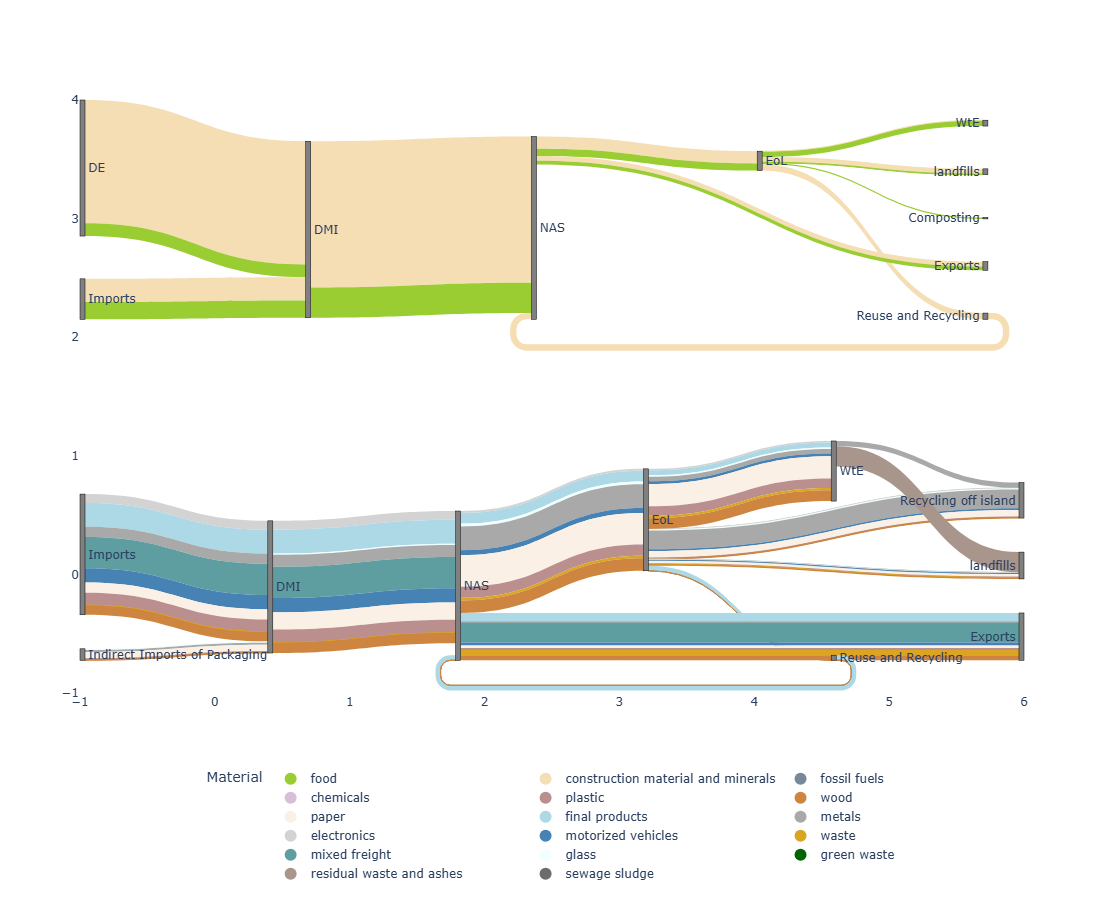

In [193]:
# dual sankey diagram, 2 rows, 1 column
fig = make_subplots(
    rows=2,
    cols=1,
    specs=[[{"type": "domain"}], 
            [{"type": "domain"}]],
    horizontal_spacing=0.08
)

# sankey 1 - high-volume materials
data1 = df.copy()

include = [ 'food', 
           'construction material and minerals']

data1 = data1[(data1['Year'] == 2022) &
              (data1['Material'].isin(include))]

node_indices ={
    "DE": 0, 
    "Imports": 1, 
    "Indirect Imports of Packaging": 2, 
    "DMI": 3, 
    "NAS": 4, 
    "Reuse and Recycling": 5, 
    "EoL": 6, 
    "Composting": 7,
    "Exports": 8, 
    "WtE": 9, 
    "Recycling off island": 10, 
    "landfills": 11
}

nodes = [None] * len(node_indices)
for name, idx in node_indices.items():
    nodes[idx] = name
    
source_indices = [node_indices[source] for source in data1['Source']]
target_indices = [node_indices[target] for target in data1['Target']]
source_indices, target_indices

fig.add_trace(
    go.Sankey(
        arrangement="snap",
        node=dict(
            pad=15,
            thickness=5,
            line=dict(color="black", width=0.5),
            label=nodes,
            color="grey"
        ),
        link=dict(
            source=[node_indices[s] for s in data1['Source']],
            target=[node_indices[t] for t in data1['Target']],
            value=data1['kilotons'],
            color=[product_colors[p] for p in data1['Material']]
        )#,
        #showlegend=False
    ),
    row=1, col=1
)

print(data1[(data1['Source'] == 'DE') | (data1['Target'] == 'DE')])

# sankey 2 - low-volume materials
data2 = df.copy()
exclude = ['green waste', 'food', 'fossil fuels',
           'sewage sludge', 'chemicals',
           'construction material and minerals']

data2 = data2[(data2['Year'] == 2022) &
              (~data2['Material'].isin(exclude))]

# nodes = [n for n in ordered_nodes 
#           if n in set(data2['Source']).union(set(data2['Target']))]

# node_indices = {node: idx for idx, node in enumerate(nodes)}
node_indices ={
    "DE": 0, 
    "Imports": 1, 
    "Indirect Imports of Packaging": 2, 
    "DMI": 3, 
    "NAS": 4, 
    "Reuse and Recycling": 5, 
    "EoL": 6, 
    "Composting": 7,
    "Exports": 8, 
    "WtE": 9, 
    "Recycling off island": 10, 
    "landfills": 11
}

nodes = [None] * len(node_indices)
for name, idx in node_indices.items():
    nodes[idx] = name
    
source_indices = [node_indices[source] for source in data2['Source']]
target_indices = [node_indices[target] for target in data2['Target']]
source_indices, target_indices

# nodes = list(set(data2['Source']).union(set(data2['Target'])))
# node_indices = {node: idx for idx, node in enumerate(nodes)}

fig.add_trace(
    go.Sankey(
        arrangement="snap",
        node=dict(
            pad=15,
            thickness=5,
            line=dict(color="black", width=0.5),
            label=nodes,
            color="grey"
        ),
        link=dict(
            source=[node_indices[s] for s in data2['Source']],
            target=[node_indices[t] for t in data2['Target']],
            value=data2['kilotons'],
            color=[product_colors[p] for p in data2['Material']]
        )#,
        #showlegend=False
    ),
    row=2, col=1
)

# same legend
for material, color in product_colors.items():
    fig.add_trace(
        go.Scatter(
            x=[None],
            y=[None],
            mode="markers",
            marker=dict(size=12, color=color),
            name=material,
            hoverinfo="none",
            showlegend=True
        )#,
        #row=2, col=1
    )

# layout
fig.update_layout(
    height=900,
    legend=dict(
        orientation="h",
        yanchor="top",
        y=-0.12,
        xanchor="center",
        x=0.5,
        title="Material",
        traceorder="normal"
    ),
    margin=dict(b=140),
    plot_bgcolor="rgba(0,0,0,0)",
    paper_bgcolor="rgba(0,0,0,0)"
)

fig.show()

In [212]:
#fig.write_html("sankeys.html")
#fig.write_image("NAS_comparison.jpg", scale=6)

### Heatmaps

In [195]:
sns.set_theme(style="white")
plt.rcParams["figure.dpi"] = 150

In [201]:
df["share"] = (
    df["kilotons"] /
    df.groupby(["Material", "Year"])["kilotons"].transform("sum")
)

In [203]:
materials = sorted(df["Material"].unique())

In [205]:
# sns.set_theme(style="white")

plt.rcParams.update({
    "figure.dpi":150,
    "font.size":11,
    "axes.titlesize":12,
    "axes.labelsize":11
})

In [207]:
strategies = [
    "reuse, recycling and composting",
    "exports for recycling",
    "WtE",
    "landfills"
]
comp_reuse["strategy"] = "reuse, recycling and composting"
F8_0["strategy"] = "exports for recycling"
F4_5["strategy"] = "WtE"
deltaS7["strategy"] = "landfills"

In [209]:
df = pd.concat([comp_reuse, F8_0, F4_5, deltaS7], ignore_index=True)

In [211]:
df["share"] = (
    df["kilotons"] /
    df.groupby(["Material", "Year"])["kilotons"].transform("sum")
)

materials = sorted(df["Material"].unique())
years = sorted(df["Year"].unique())

In [215]:
base_cmap = sns.color_palette("flare", as_cmap=True)
#https://seaborn.pydata.org/tutorial/color_palettes.html

C:\Users\linsmasa\AppData\Local\Temp\ipykernel_30572\1896347636.py:27: FutureWarning:

DataFrame.applymap has been deprecated. Use DataFrame.map instead.

C:\Users\linsmasa\AppData\Local\Temp\ipykernel_30572\1896347636.py:27: FutureWarning:

DataFrame.applymap has been deprecated. Use DataFrame.map instead.

C:\Users\linsmasa\AppData\Local\Temp\ipykernel_30572\1896347636.py:27: FutureWarning:

DataFrame.applymap has been deprecated. Use DataFrame.map instead.

C:\Users\linsmasa\AppData\Local\Temp\ipykernel_30572\1896347636.py:27: FutureWarning:

DataFrame.applymap has been deprecated. Use DataFrame.map instead.

C:\Users\linsmasa\AppData\Local\Temp\ipykernel_30572\1896347636.py:27: FutureWarning:

DataFrame.applymap has been deprecated. Use DataFrame.map instead.

C:\Users\linsmasa\AppData\Local\Temp\ipykernel_30572\1896347636.py:27: FutureWarning:

DataFrame.applymap has been deprecated. Use DataFrame.map instead.

C:\Users\linsmasa\AppData\Local\Temp\ipykernel_30572\1896347636.py:27:

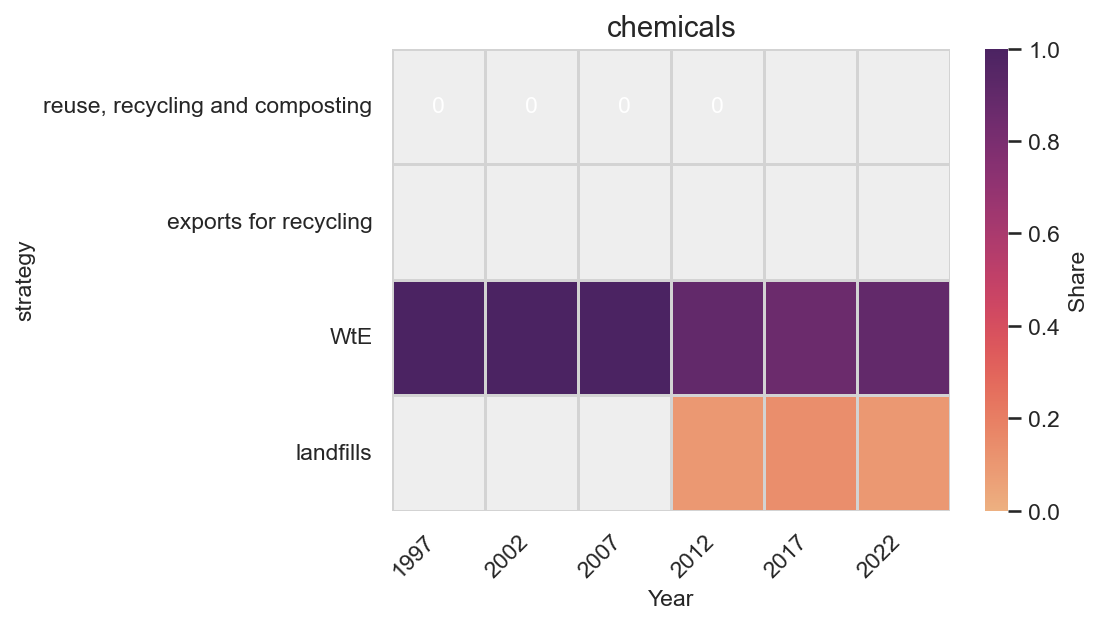

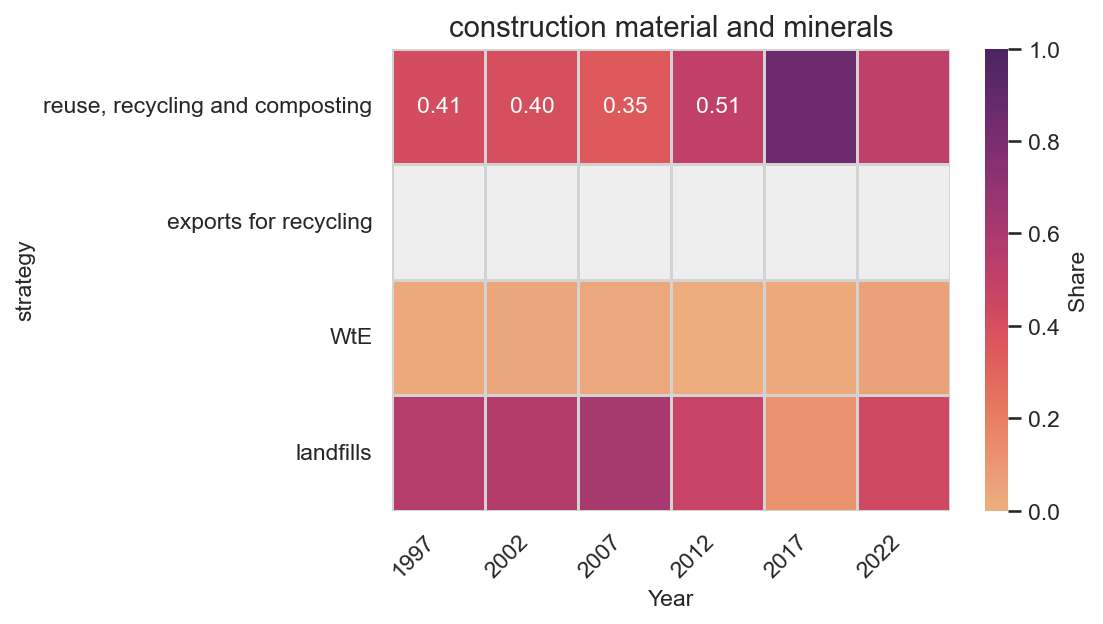

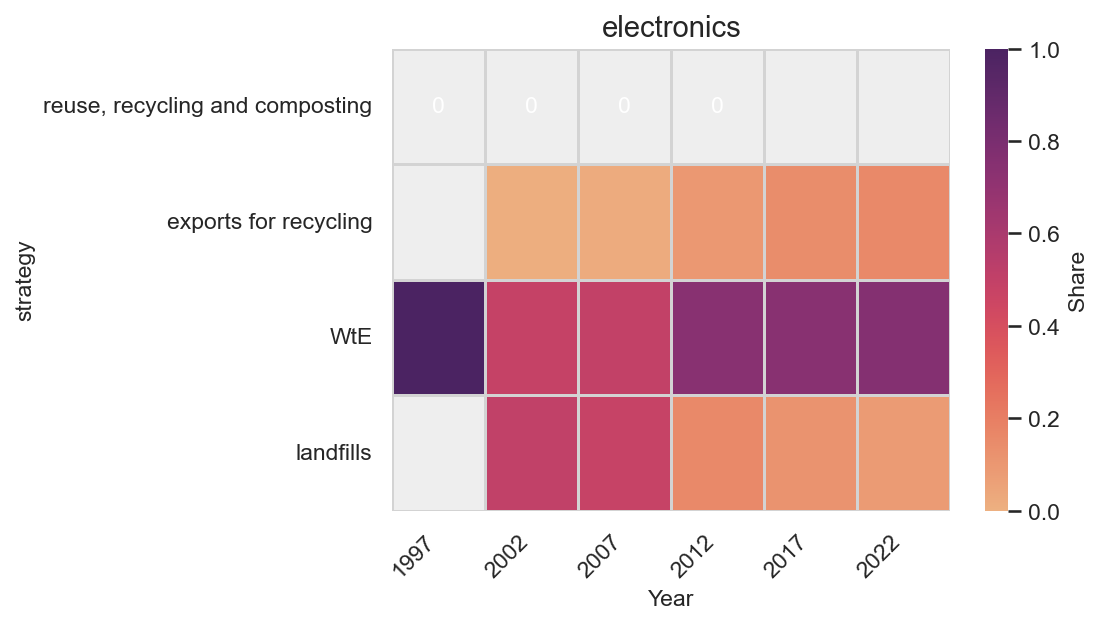

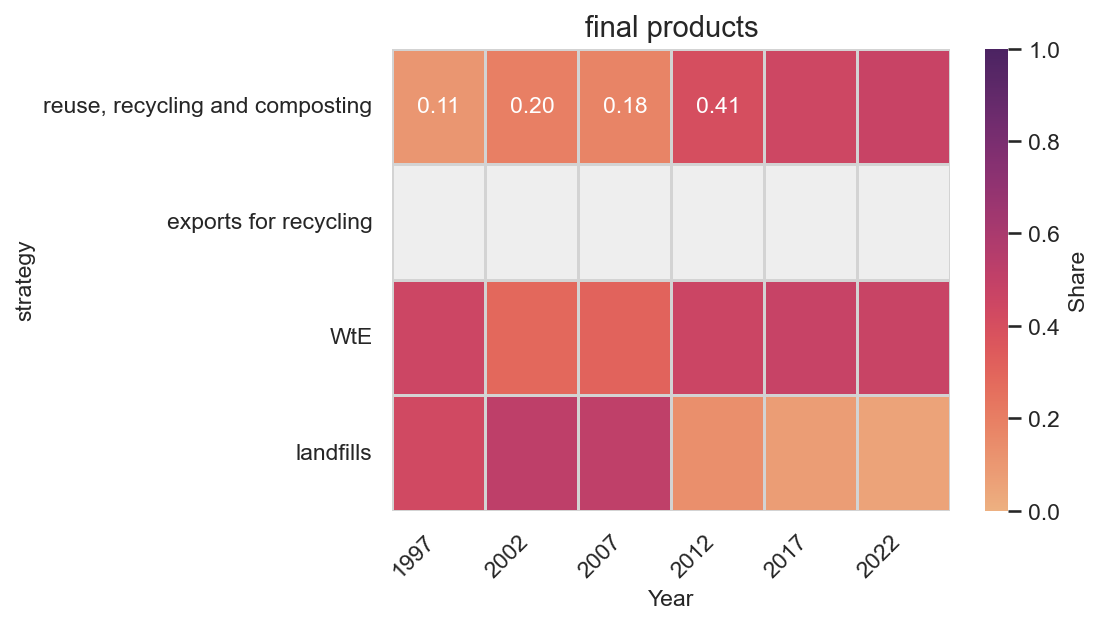

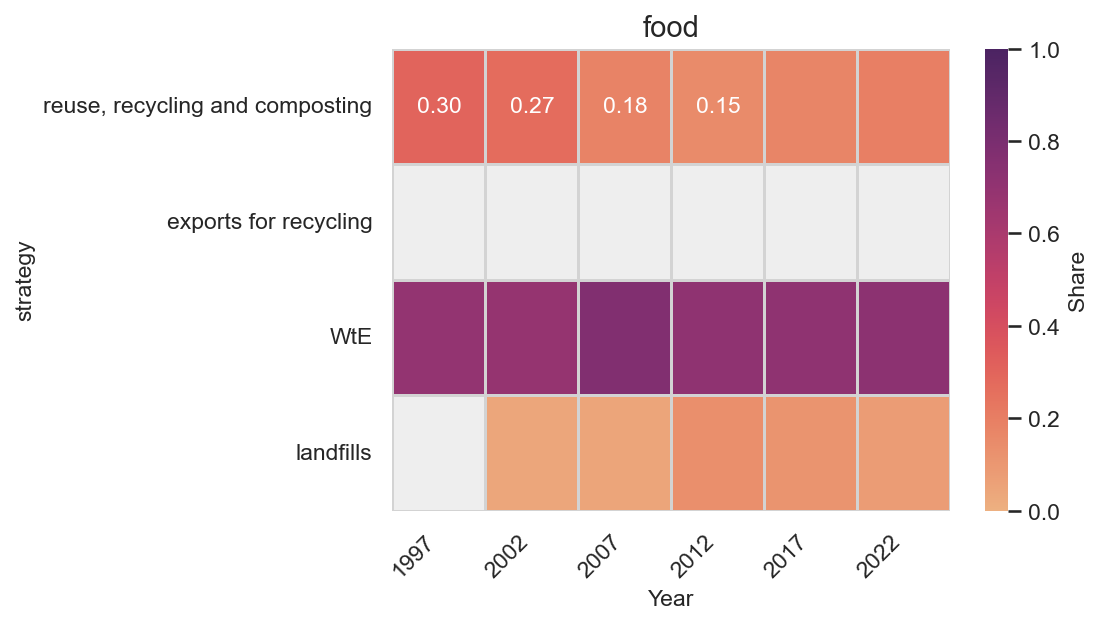

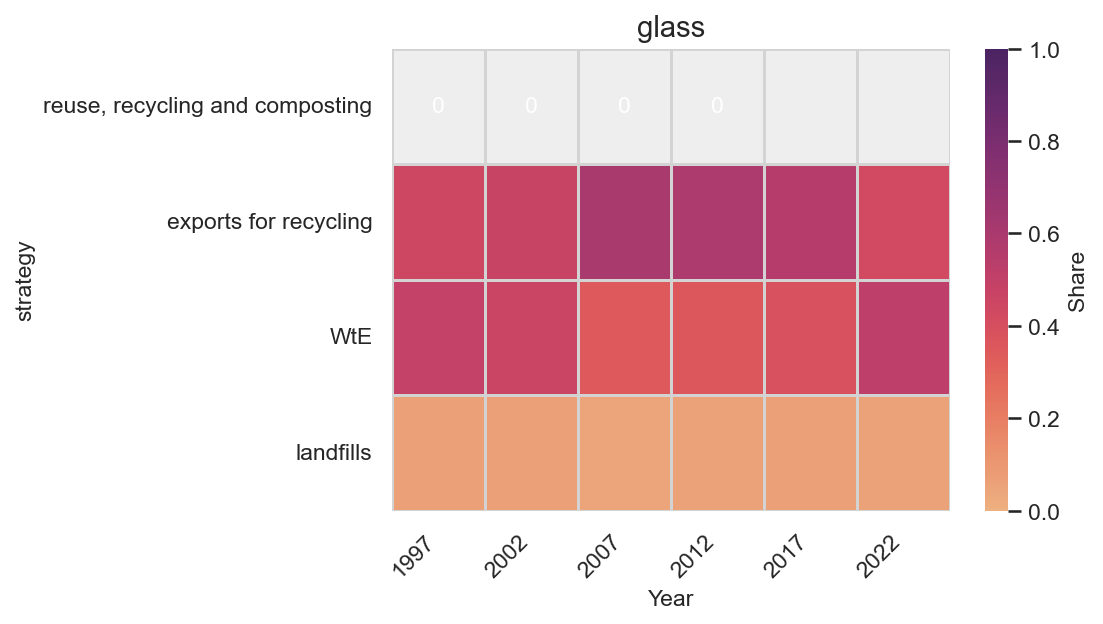

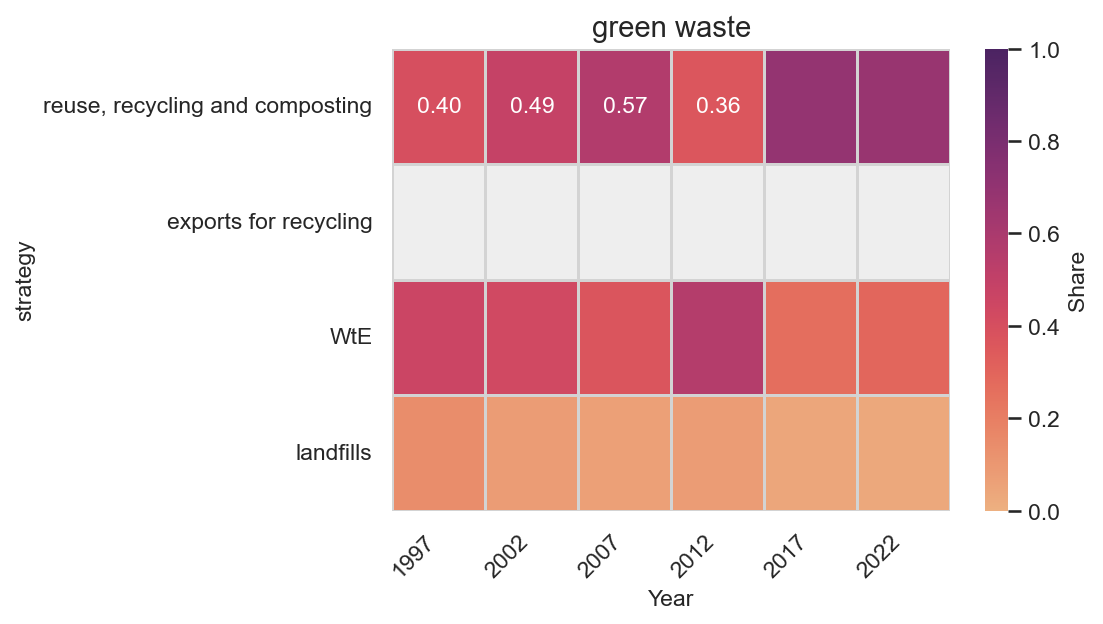

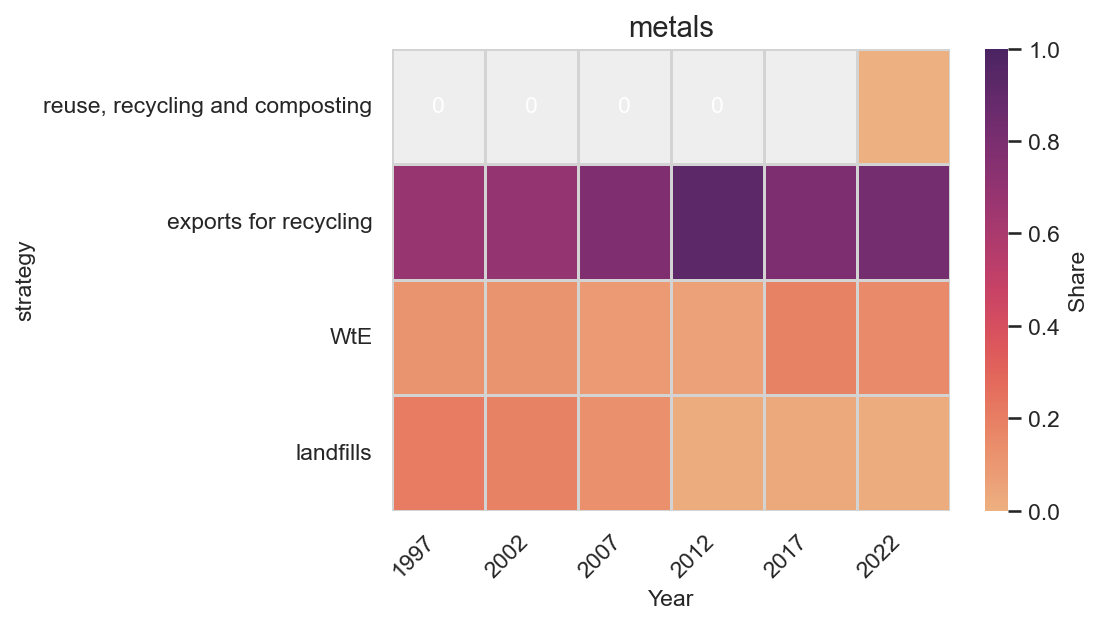

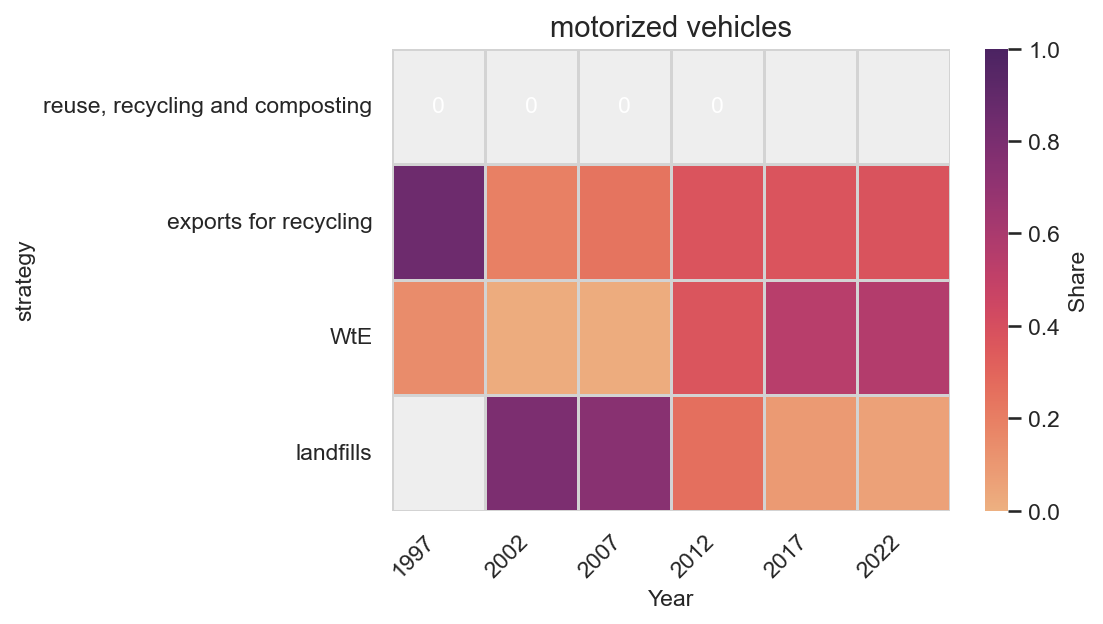

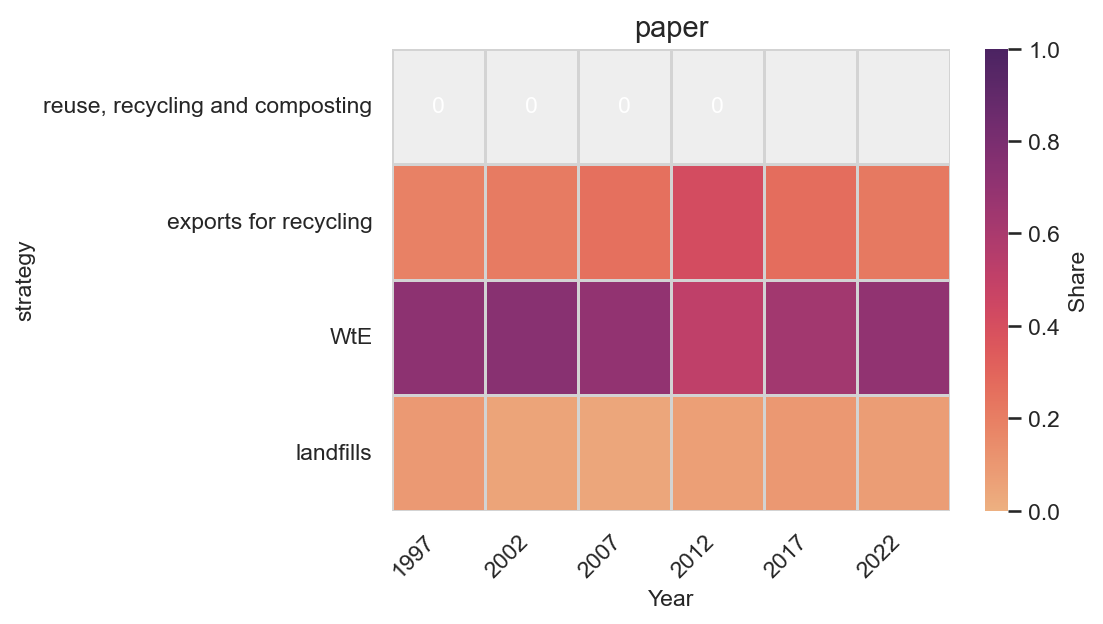

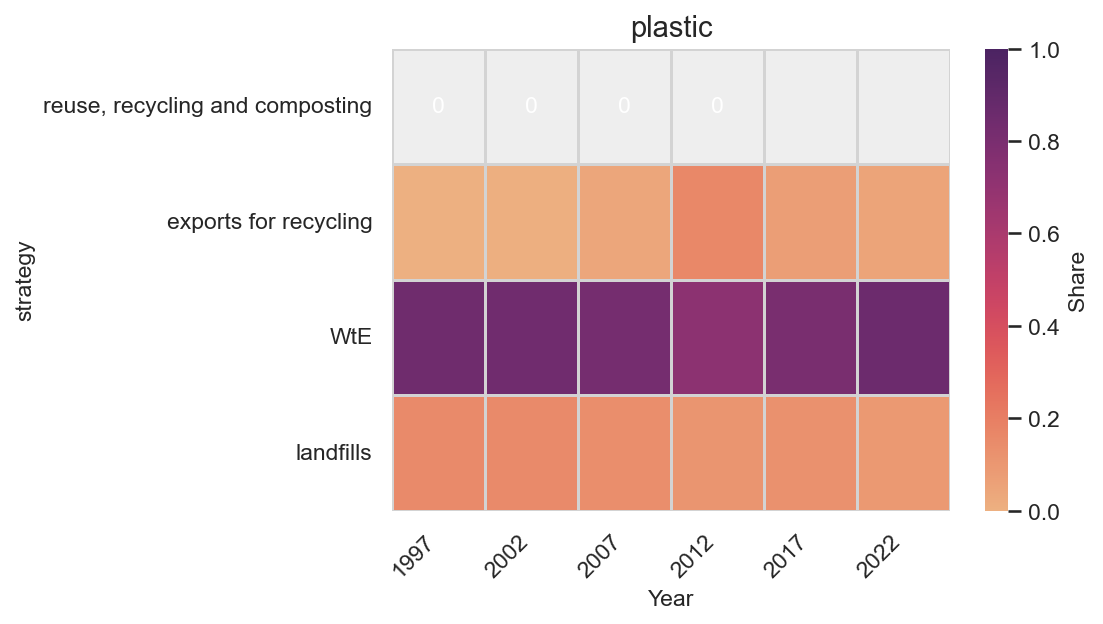

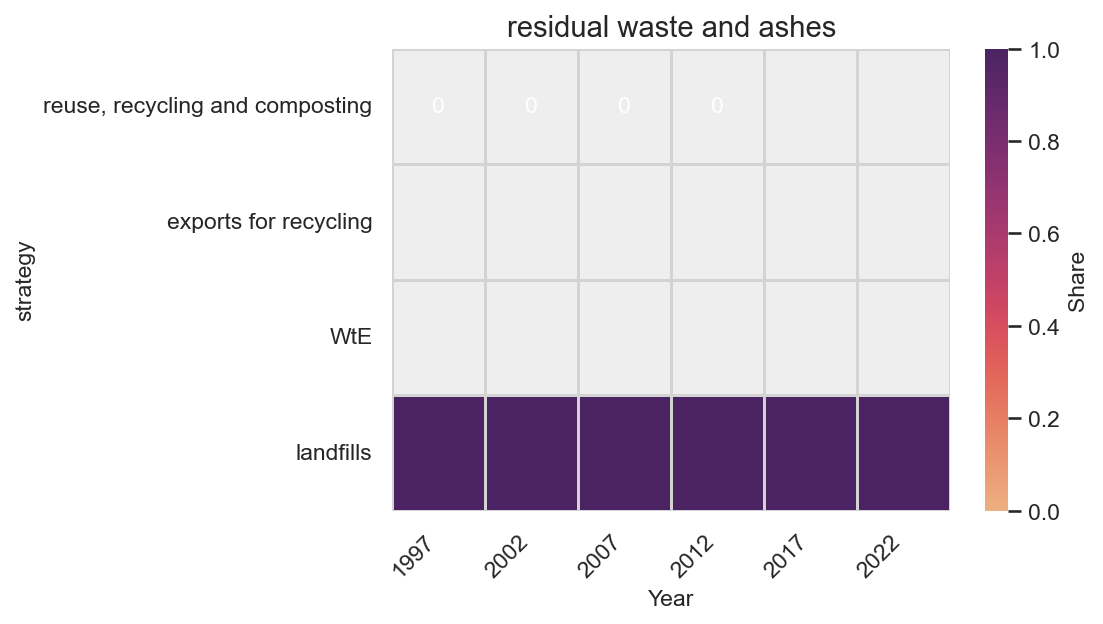

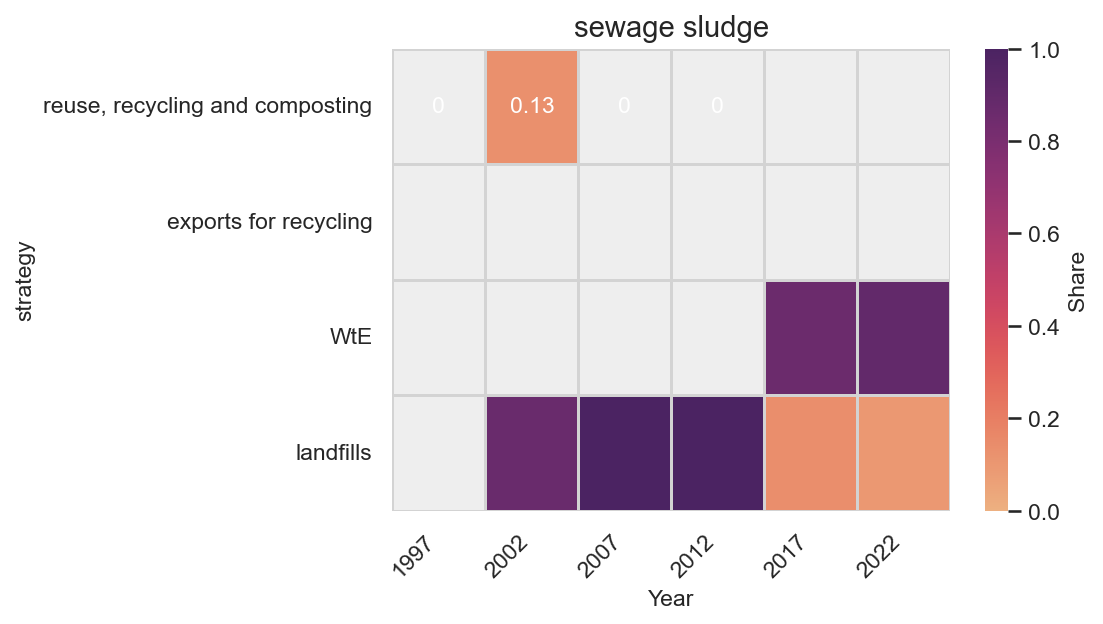

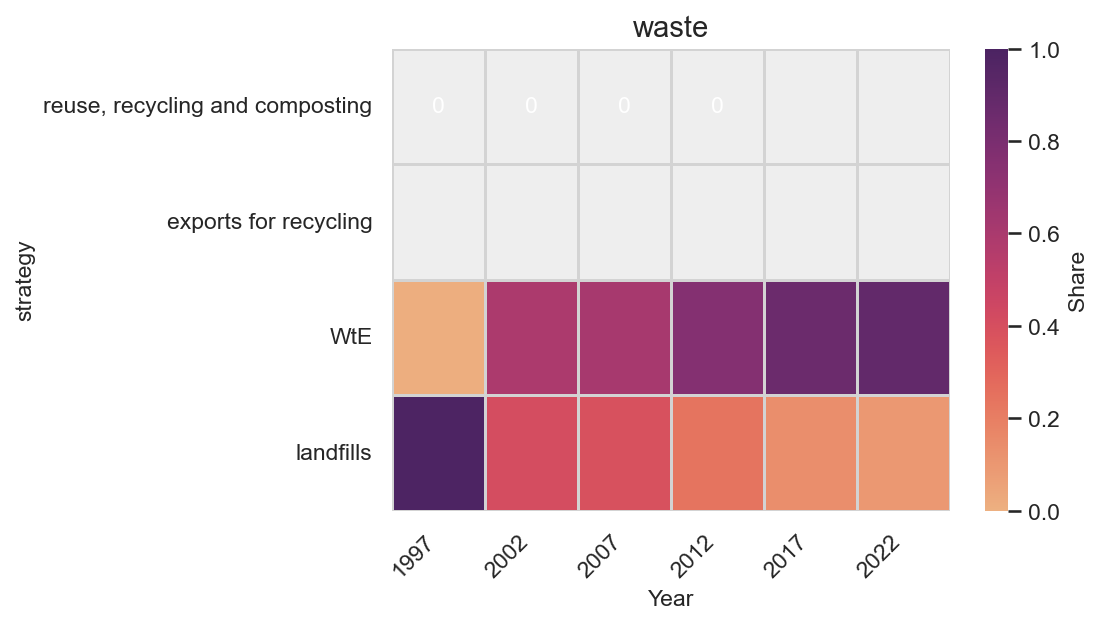

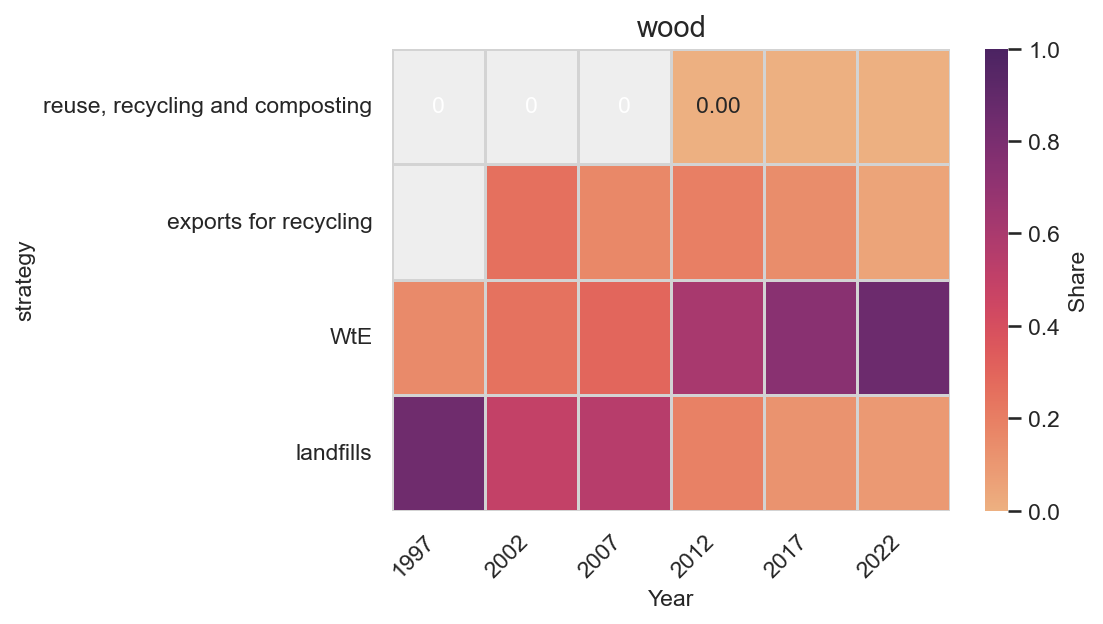

In [219]:
# output folder for single heatmaps
output_folder = "heatmaps_materials"
os.makedirs(output_folder, exist_ok=True)


for material in materials:

    data_material = df[df["Material"] == material]

    heatmap_data = data_material.pivot_table(
        index="strategy",
        columns="Year",
        values="share"
    )

    heatmap_data = heatmap_data.reindex(
        index=strategies,
        columns=years
    ).fillna(0)

    annot = heatmap_data.applymap(
        lambda x: "0" if x == 0 else f"{x:.2f}"
    )

    mask = heatmap_data == 0

    fig, ax = plt.subplots(
        figsize=(6, 4)
    )

    sns.heatmap(
        heatmap_data,
        ax=ax,
        cmap="flare",
        vmin=0,
        vmax=1,   # same scale for all heat maps
        linewidths=0.5,
        linecolor="lightgrey",
        annot=annot,
        fmt="",
        mask=mask,
        cbar=True,
        cbar_kws={
            "label": "Share"
        }
    )

    sns.heatmap(
        heatmap_data,
        ax=ax,
        cmap=ListedColormap(["#eeeeee"]),
        mask=~mask,
        cbar=False,
        linewidths=0.5,
        linecolor="lightgrey"
    )

    ax.set_title(material, fontsize=14)

    ax.set_xlabel("Year")
    #ax.set_ylabel("Strategy")

    ax.set_xticklabels(
        years,
        rotation=45,
        ha="right"
    )


    # save images
    # filename = f"{output_folder}/heatmap_{material}.jpg"

    # plt.savefig(
    #     filename,
    #     dpi=600,
    #     bbox_inches="tight"
    # )

    # plt.close()


#print("All heatmaps are saved.")